# MF-DCCA Network + LS-SVM Collective Market Movement Prediction

**Purpose**: Construct a Multifractal Detrended Cross-Correlation Analysis (MF-DCCA) network
of financial assets, separate the analysis into **upward** vs **downward** market regimes,
and use a **Least Squares SVM (LS-SVM)** to collectively model market direction and produce
forecasts and risk metrics.

**References**:
- Zhou (2008) — Multifractal detrended cross-correlation analysis
- Podobnik & Stanley (2008) — Detrended cross-correlation analysis
- Suykens & Vandewalle (1999) — Least Squares Support Vector Machines

In [1]:
# Cell 1 — Imports & Dependencies
import subprocess, sys

for pkg in ["networkx", "seaborn"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import networkx as nx
from scipy.stats import linregress
from scipy.linalg import solve
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from pathlib import Path
from itertools import combinations
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "font.size": 10,
})

print("All imports successful.")

All imports successful.


In [2]:
# Cell 2 — Configuration

# Ticker subset (20 tickers for computational tractability)
TICKERS = [
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",      # Tech
    "JPM", "GS", "BAC", "V", "MA",                 # Financials
    "JNJ", "UNH", "PFE",                           # Healthcare
    "XOM", "CVX",                                   # Energy
    "KO", "PG", "WMT",                              # Consumer
    "BTC-USD", "GC_F",                              # Crypto & Gold
]

DATA_DIR = Path("stock_csv_data")
OUT_DIR  = Path("mf_dcca_outputs")
OUT_DIR.mkdir(exist_ok=True)

# MF-DCCA parameters
POLY_ORD   = 1                                      # linear detrending
Q_VALS     = np.array([-5, -3, -1, 0.5, 1, 2, 3, 5])
SCALE_MIN  = 10
SCALE_MAX  = 250
N_SCALES   = 15
SCALES     = np.unique(np.logspace(
                 np.log10(SCALE_MIN), np.log10(SCALE_MAX), N_SCALES
             ).astype(int))

# Regime parameters
REGIME_WINDOW = 20   # rolling window for regime classification

# LS-SVM parameters
LSSVM_GAMMA  = 1.0   # regularisation
LSSVM_SIGMA  = 1.0   # RBF bandwidth
TRAIN_START  = 500    # minimum training window (days)
RETRAIN_FREQ = 60     # retrain every N days in walk-forward

# Network parameters
RHO_THRESHOLD = 0.3   # edge threshold for filtered networks
NETWORK_SCALE = 20     # scale (in trading days) for rho_DCCA network

print(f"Tickers:  {len(TICKERS)}")
print(f"Scales:   {SCALES}")
print(f"q-values: {Q_VALS}")

Tickers:  20
Scales:   [ 10  12  15  19  25  31  39  49  62  79  99 125 157 198 249]
q-values: [-5.  -3.  -1.   0.5  1.   2.   3.   5. ]


In [3]:
# Cell 3 — Load Price Data & Compute Log-Returns

prices = {}
returns = {}

for ticker in TICKERS:
    csv_path = DATA_DIR / f"{ticker}_data.csv"
    if not csv_path.exists():
        print(f"  Warning: {csv_path} not found, skipping {ticker}")
        continue
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").set_index("Date")
    close = pd.to_numeric(df["Close"], errors="coerce").dropna()
    prices[ticker]  = close
    returns[ticker] = np.log(close / close.shift(1)).dropna()

# Align on common dates
common_dates = None
for t in list(returns.keys()):
    idx = returns[t].index
    common_dates = idx if common_dates is None else common_dates.intersection(idx)

for t in list(returns.keys()):
    returns[t] = returns[t].loc[common_dates]
    prices[t]  = prices[t].loc[common_dates]

TICKERS = list(returns.keys())  # update in case any were skipped
N_ASSETS = len(TICKERS)

ret_df   = pd.DataFrame(returns)
price_df = pd.DataFrame(prices)

print(f"Loaded {N_ASSETS} tickers, {len(common_dates)} common trading days")
print(f"Date range: {common_dates.min().date()} to {common_dates.max().date()}")
print(f"Tickers: {TICKERS}")

Loaded 20 tickers, 2904 common trading days
Date range: 2014-09-18 to 2026-04-10
Tickers: ['AAPL', 'MSFT', 'GOOG', 'AMZN', 'NVDA', 'JPM', 'GS', 'BAC', 'V', 'MA', 'JNJ', 'UNH', 'PFE', 'XOM', 'CVX', 'KO', 'PG', 'WMT', 'BTC-USD', 'GC_F']


---
## Part 2 — MF-DCCA Core Engine

Implements the Multifractal Detrended Cross-Correlation Analysis (MF-DCCA)
following Zhou (2008). For two series x and y:

1. Compute profiles (cumulative sums of demeaned series)
2. Divide into non-overlapping segments of size s
3. Fit polynomial trends and compute detrended cross-covariance
4. Compute q-th order fluctuation function F_xy(q, s)
5. Extract generalised cross-Hurst exponent h_xy(q) via log-log regression
6. Compute DCCA coefficient rho_DCCA(s)

In [4]:
# Cell 4 — MF-DCCA Implementation

def _profile(x):
    # Cumulative sum of demeaned series (integration step).
    return np.cumsum(x - np.mean(x))


def _detrended_cross_covariance(Xp, Yp, s, poly_ord=1):
    # Compute detrended cross-covariance F^2_xy(s) for a single scale s.
    N = len(Xp)
    n_seg = N // s
    if n_seg < 1:
        return np.array([np.nan])

    f2 = np.zeros(2 * n_seg)
    t = np.arange(s)

    # Forward segments
    for v in range(n_seg):
        seg_x = Xp[v * s : (v + 1) * s]
        seg_y = Yp[v * s : (v + 1) * s]
        cx = np.polyfit(t, seg_x, poly_ord)
        cy = np.polyfit(t, seg_y, poly_ord)
        res_x = seg_x - np.polyval(cx, t)
        res_y = seg_y - np.polyval(cy, t)
        f2[v] = np.mean(res_x * res_y)

    # Backward segments (start from end)
    for v in range(n_seg):
        seg_x = Xp[N - (v + 1) * s : N - v * s]
        seg_y = Yp[N - (v + 1) * s : N - v * s]
        cx = np.polyfit(t, seg_x, poly_ord)
        cy = np.polyfit(t, seg_y, poly_ord)
        res_x = seg_x - np.polyval(cx, t)
        res_y = seg_y - np.polyval(cy, t)
        f2[n_seg + v] = np.mean(res_x * res_y)

    return f2


def mf_dcca(x, y, q_vals, scales, poly_ord=1):
    # Full MF-DCCA analysis for two series.
    # Returns Fq (len(q_vals) x len(scales)) and hq (len(q_vals),).
    Xp = _profile(x)
    Yp = _profile(y)

    n_q = len(q_vals)
    n_s = len(scales)
    Fq  = np.full((n_q, n_s), np.nan)

    for j, s in enumerate(scales):
        f2 = _detrended_cross_covariance(Xp, Yp, s, poly_ord)
        if np.all(np.isnan(f2)):
            continue

        for i, q in enumerate(q_vals):
            if abs(q) < 1e-10:
                # q -> 0: geometric mean
                valid = f2[f2 != 0]
                if len(valid) > 0:
                    Fq[i, j] = np.exp(0.5 * np.mean(np.log(np.abs(valid))))
                else:
                    Fq[i, j] = np.nan
            else:
                abs_f2 = np.abs(f2)
                abs_f2[abs_f2 == 0] = np.nan
                valid_mask = ~np.isnan(abs_f2)
                if valid_mask.sum() > 0:
                    val = np.nanmean(abs_f2[valid_mask] ** (q / 2.0))
                    if val > 0:
                        Fq[i, j] = val ** (1.0 / q) if abs(q) > 1e-10 else val
                    else:
                        Fq[i, j] = np.nan

    # Compute h(q) via log-log regression
    ln_s = np.log(scales)
    hq = np.full(n_q, np.nan)
    for i in range(n_q):
        valid = np.isfinite(Fq[i])
        if valid.sum() >= 3:
            slope, _, _, _, _ = linregress(ln_s[valid], np.log(Fq[i, valid]))
            hq[i] = slope

    return Fq, hq


def dcca_coefficient(x, y, s, poly_ord=1):
    # Compute the DCCA cross-correlation coefficient rho_DCCA(s).
    # rho_DCCA(s) = F^2_xy(s) / sqrt(F^2_xx(s) * F^2_yy(s))
    Xp = _profile(x)
    Yp = _profile(y)

    f2_xy = _detrended_cross_covariance(Xp, Yp, s, poly_ord)
    f2_xx = _detrended_cross_covariance(Xp, Xp, s, poly_ord)
    f2_yy = _detrended_cross_covariance(Yp, Yp, s, poly_ord)

    num = np.mean(f2_xy)
    den = np.sqrt(np.abs(np.mean(f2_xx)) * np.abs(np.mean(f2_yy)))

    if den < 1e-15:
        return 0.0
    return num / den


def dcca_coefficient_multiscale(x, y, scales, poly_ord=1):
    # Compute rho_DCCA across multiple scales.
    return np.array([dcca_coefficient(x, y, s, poly_ord) for s in scales])


print("MF-DCCA engine defined.")

MF-DCCA engine defined.


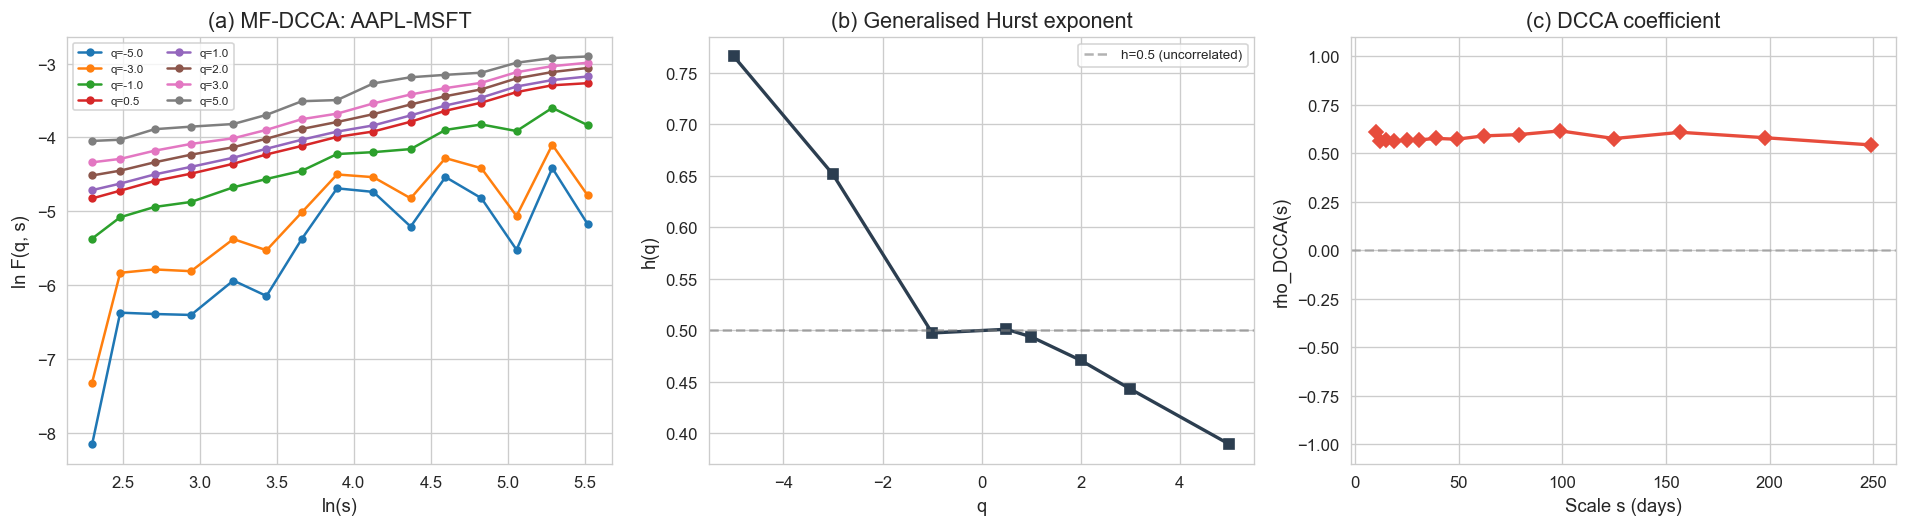

  h(q=2) = 0.4707  (bivariate Hurst exponent)
  Delta_h = 0.3764  (multifractal width)
  rho_DCCA(s=20) = 0.5607


In [5]:
# Cell 5 — Validation: MF-DCCA on AAPL vs MSFT

pair = ("AAPL", "MSFT")
x = returns[pair[0]].values
y = returns[pair[1]].values

Fq_val, hq_val = mf_dcca(x, y, Q_VALS, SCALES, POLY_ORD)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Log-log fluctuation functions
ax = axes[0]
for i, q in enumerate(Q_VALS):
    valid = np.isfinite(Fq_val[i])
    if valid.sum() >= 2:
        ax.plot(np.log(SCALES[valid]), np.log(Fq_val[i, valid]),
                "o-", markersize=4, label=f"q={q:.1f}")
ax.set_xlabel("ln(s)")
ax.set_ylabel("ln F(q, s)")
ax.set_title(f"(a) MF-DCCA: {pair[0]}-{pair[1]}")
ax.legend(fontsize=7, ncol=2)

# (b) h(q) spectrum
ax = axes[1]
valid_hq = np.isfinite(hq_val)
ax.plot(Q_VALS[valid_hq], hq_val[valid_hq], "s-", color="#2c3e50", linewidth=2)
ax.axhline(0.5, ls="--", color="grey", alpha=0.6, label="h=0.5 (uncorrelated)")
ax.set_xlabel("q")
ax.set_ylabel("h(q)")
ax.set_title("(b) Generalised Hurst exponent")
ax.legend(fontsize=8)

# (c) rho_DCCA across scales
rho_vals = dcca_coefficient_multiscale(x, y, SCALES, POLY_ORD)
ax = axes[2]
ax.plot(SCALES, rho_vals, "D-", color="#e74c3c", linewidth=2)
ax.set_xlabel("Scale s (days)")
ax.set_ylabel("rho_DCCA(s)")
ax.set_title("(c) DCCA coefficient")
ax.axhline(0, ls="--", color="grey", alpha=0.5)
ax.set_ylim(-1.1, 1.1)

plt.tight_layout()
plt.savefig(OUT_DIR / "validation_mfdcca.png", dpi=150, bbox_inches="tight")
plt.show()

h2_idx = np.where(Q_VALS == 2)[0]
if len(h2_idx) > 0:
    print(f"  h(q=2) = {hq_val[h2_idx[0]]:.4f}  (bivariate Hurst exponent)")
print(f"  Delta_h = {np.nanmax(hq_val) - np.nanmin(hq_val):.4f}  (multifractal width)")
print(f"  rho_DCCA(s={NETWORK_SCALE}) = {dcca_coefficient(x, y, NETWORK_SCALE, POLY_ORD):.4f}")

---
## Part 3 — Regime Splitting (Upward / Downward)

We define an equally-weighted market index from all selected tickers,
then classify each day into **Up** or **Down** regimes using a rolling
window of the index returns.

In [6]:
# Cell 6 — Regime Classification

# Equally-weighted market index
market_ret = ret_df.mean(axis=1)

# Rolling regime classification
# Regime = sign of rolling mean return over REGIME_WINDOW days
rolling_mean = market_ret.rolling(window=REGIME_WINDOW, center=False).mean()
regime = (rolling_mean >= 0).astype(int)  # 1 = Up, 0 = Down
regime = regime.dropna()

# Align returns with regime
common = ret_df.index.intersection(regime.index)
regime  = regime.loc[common]
ret_aligned = ret_df.loc[common]

up_mask   = regime == 1
down_mask = regime == 0

n_up   = up_mask.sum()
n_down = down_mask.sum()

print(f"Regime classification ({REGIME_WINDOW}-day rolling window):")
print(f"  Up days  : {n_up}  ({100*n_up/len(regime):.1f}%)")
print(f"  Down days: {n_down}  ({100*n_down/len(regime):.1f}%)")

# Extract returns for each regime
ret_up   = ret_aligned.loc[up_mask]
ret_down = ret_aligned.loc[down_mask]

print(f"  Up regime:   {ret_up.index.min().date()} to {ret_up.index.max().date()}")
print(f"  Down regime: {ret_down.index.min().date()} to {ret_down.index.max().date()}")

Regime classification (20-day rolling window):
  Up days  : 2028  (69.8%)
  Down days: 876  (30.2%)
  Up regime:   2014-10-28 to 2026-04-10
  Down regime: 2014-09-18 to 2026-04-07


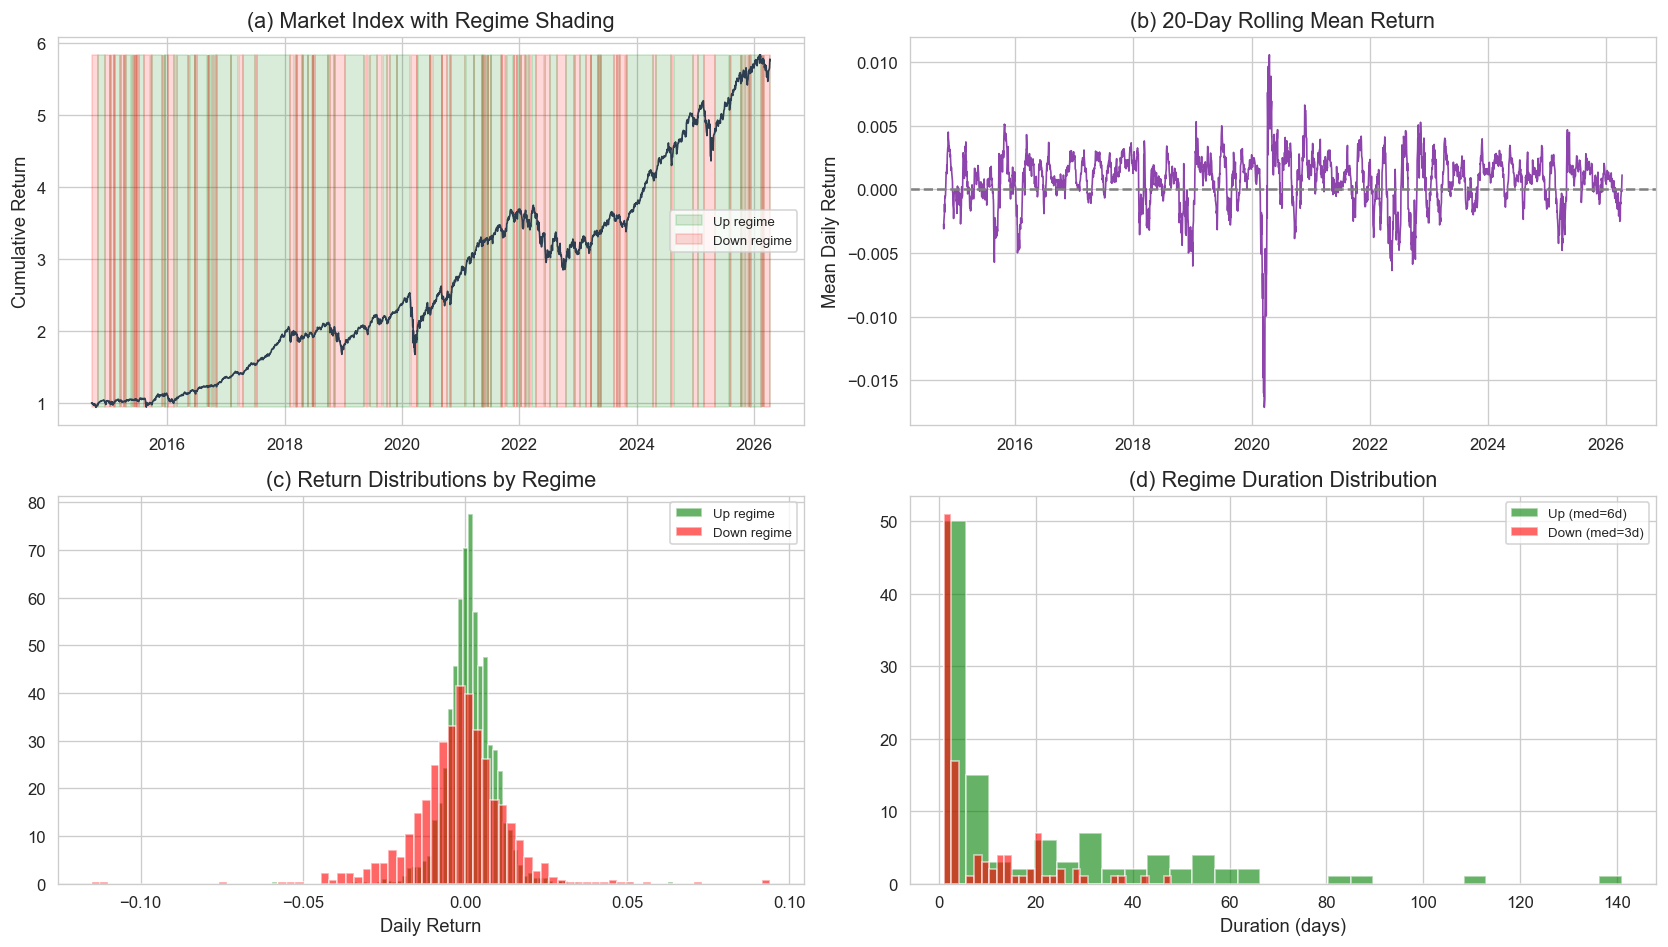

In [7]:
# Cell 7 — Regime Statistics & Visualisation

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# (a) Market index cumulative return with regime shading
ax = axes[0, 0]
cum_ret = (1 + market_ret.loc[common]).cumprod()
ax.plot(cum_ret.index, cum_ret.values, color="#2c3e50", linewidth=1)
ax.fill_between(cum_ret.index, cum_ret.values.min(), cum_ret.values.max(),
                where=up_mask.values, alpha=0.15, color="green", label="Up regime")
ax.fill_between(cum_ret.index, cum_ret.values.min(), cum_ret.values.max(),
                where=down_mask.values, alpha=0.15, color="red", label="Down regime")
ax.set_title("(a) Market Index with Regime Shading")
ax.set_ylabel("Cumulative Return")
ax.legend(fontsize=8)

# (b) Rolling mean return
ax = axes[0, 1]
ax.plot(rolling_mean.loc[common].index, rolling_mean.loc[common].values,
        color="#8e44ad", linewidth=1)
ax.axhline(0, ls="--", color="grey")
ax.set_title(f"(b) {REGIME_WINDOW}-Day Rolling Mean Return")
ax.set_ylabel("Mean Daily Return")

# (c) Distribution of returns by regime
ax = axes[1, 0]
up_rets = market_ret.loc[common][up_mask].values
dn_rets = market_ret.loc[common][down_mask].values
ax.hist(up_rets, bins=80, alpha=0.6, color="green", label="Up regime", density=True)
ax.hist(dn_rets, bins=80, alpha=0.6, color="red", label="Down regime", density=True)
ax.set_title("(c) Return Distributions by Regime")
ax.set_xlabel("Daily Return")
ax.legend(fontsize=8)

# (d) Regime duration distribution
regime_changes = regime.diff().fillna(0).abs()
regime_blocks = (regime_changes.cumsum())
durations = regime.groupby(regime_blocks).agg(["count", "first"])
up_dur  = durations[durations["first"] == 1]["count"]
dn_dur  = durations[durations["first"] == 0]["count"]

ax = axes[1, 1]
ax.hist(up_dur, bins=30, alpha=0.6, color="green", label=f"Up (med={up_dur.median():.0f}d)")
ax.hist(dn_dur, bins=30, alpha=0.6, color="red", label=f"Down (med={dn_dur.median():.0f}d)")
ax.set_title("(d) Regime Duration Distribution")
ax.set_xlabel("Duration (days)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT_DIR / "regime_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Part 4 — MF-DCCA Network Construction

Compute pairwise rho_DCCA matrices for the **full sample**, **up regime**, and
**down regime**, then construct and visualise the cross-correlation networks.

In [8]:
# Cell 8 — Compute Pairwise rho_DCCA Matrices

def compute_rho_matrix(ret_data, tickers, scale, poly_ord=1):
    # Compute the NxN rho_DCCA matrix for given return data at a fixed scale.
    n = len(tickers)
    rho = np.eye(n)

    pairs = list(combinations(range(n), 2))
    total = len(pairs)

    for k, (i, j) in enumerate(pairs):
        if (k + 1) % 20 == 0 or k == total - 1:
            print(f"    pair {k+1}/{total}", end="\r")
        xi = ret_data[tickers[i]].values
        xj = ret_data[tickers[j]].values

        # Need enough data for the scale
        if len(xi) < 2 * scale:
            rho[i, j] = rho[j, i] = 0.0
            continue

        rho_val = dcca_coefficient(xi, xj, scale, poly_ord)
        rho[i, j] = rho_val
        rho[j, i] = rho_val

    print()
    return rho


print("Computing rho_DCCA matrices (this may take a few minutes)...")

print("  Full sample:")
rho_full = compute_rho_matrix(ret_aligned, TICKERS, NETWORK_SCALE, POLY_ORD)

print("  Up regime:")
rho_up = compute_rho_matrix(ret_up, TICKERS, NETWORK_SCALE, POLY_ORD)

print("  Down regime:")
rho_down = compute_rho_matrix(ret_down, TICKERS, NETWORK_SCALE, POLY_ORD)

print("Done!")

Computing rho_DCCA matrices (this may take a few minutes)...
  Full sample:
    pair 190/190
  Up regime:
    pair 190/190
  Down regime:
    pair 190/190
Done!


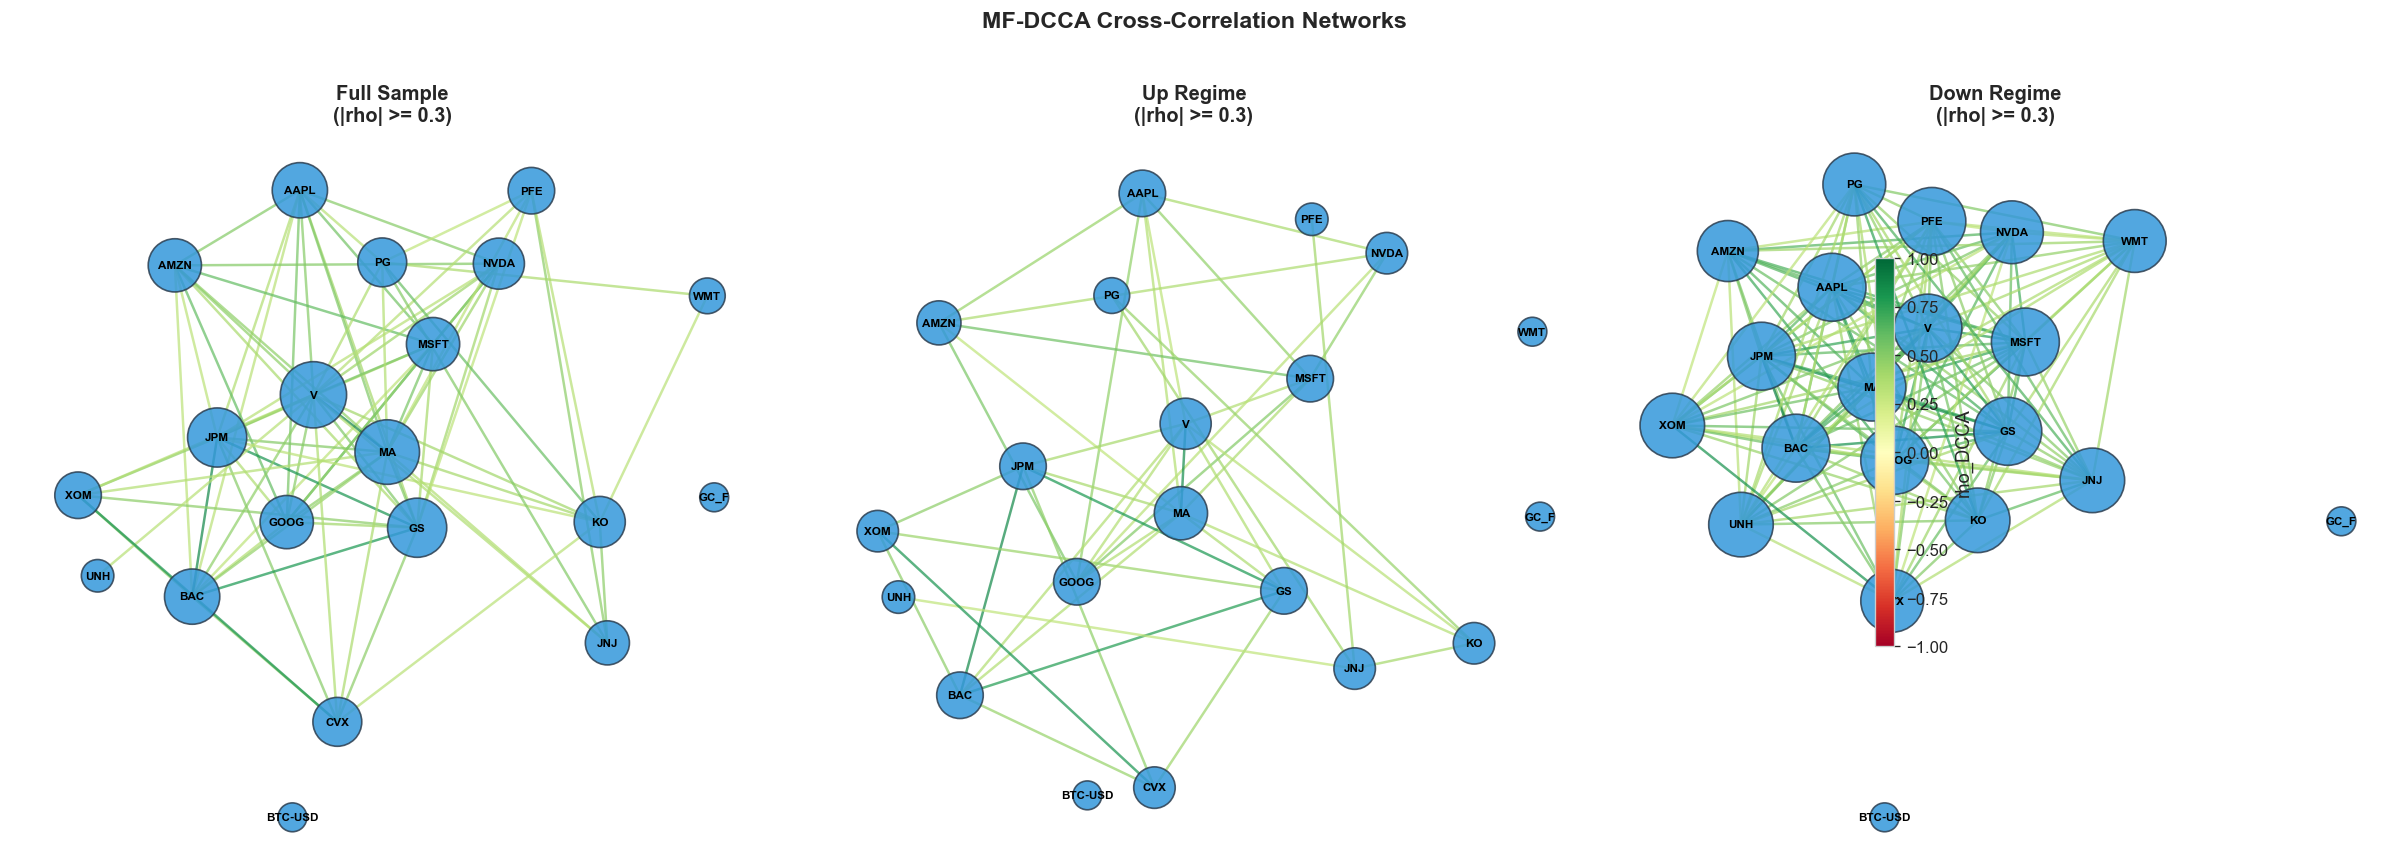

In [9]:
# Cell 9 — Network Visualisation

def build_graph(rho_matrix, tickers, threshold=0.3):
    # Build a networkx graph from a rho_DCCA matrix with thresholding.
    G = nx.Graph()
    G.add_nodes_from(tickers)
    n = len(tickers)
    for i in range(n):
        for j in range(i + 1, n):
            w = rho_matrix[i, j]
            if abs(w) >= threshold:
                G.add_edge(tickers[i], tickers[j], weight=w)
    return G


def draw_network(G, ax, title, cmap="RdYlGn"):
    # Draw the network with edge colours proportional to rho_DCCA.
    if len(G.edges) == 0:
        ax.set_title(f"{title}\n(no edges above threshold)")
        ax.axis("off")
        return None

    pos = nx.spring_layout(G, seed=42, k=1.5)
    edges = G.edges(data=True)
    weights = [d["weight"] for _, _, d in edges]

    # Node sizes proportional to degree
    degrees = dict(G.degree())
    node_sizes = [300 + 80 * degrees[n] for n in G.nodes()]

    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes,
                           node_color="#3498db", alpha=0.85, edgecolors="#2c3e50")
    edge_coll = nx.draw_networkx_edges(G, pos, ax=ax, width=1.5,
                                        edge_color=weights, edge_cmap=plt.cm.get_cmap(cmap),
                                        edge_vmin=-1, edge_vmax=1, alpha=0.7)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_weight="bold")

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")
    return edge_coll


G_full = build_graph(rho_full, TICKERS, RHO_THRESHOLD)
G_up   = build_graph(rho_up, TICKERS, RHO_THRESHOLD)
G_down = build_graph(rho_down, TICKERS, RHO_THRESHOLD)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

draw_network(G_full, axes[0], f"Full Sample\n(|rho| >= {RHO_THRESHOLD})")
draw_network(G_up,   axes[1], f"Up Regime\n(|rho| >= {RHO_THRESHOLD})")
ec = draw_network(G_down, axes[2], f"Down Regime\n(|rho| >= {RHO_THRESHOLD})")

if ec is not None:
    sm = plt.cm.ScalarMappable(cmap=plt.cm.get_cmap("RdYlGn"),
                                norm=plt.Normalize(vmin=-1, vmax=1))
    sm.set_array([])
    fig.colorbar(sm, ax=axes, shrink=0.6, label="rho_DCCA")

plt.suptitle("MF-DCCA Cross-Correlation Networks", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "dcca_networks.png", dpi=150, bbox_inches="tight")
plt.show()

Network Topology Comparison:
             Nodes  Edges Density Avg Degree Avg Clustering Avg Path Length  Components
Network                                                                                
Full Sample     20     76   0.400       7.60          0.693           1.56*           3
Up Regime       20     41   0.216       4.10          0.545           2.39*           4
Down Regime     20    141   0.742      14.10          0.837           1.08*           3

* = computed on largest connected component


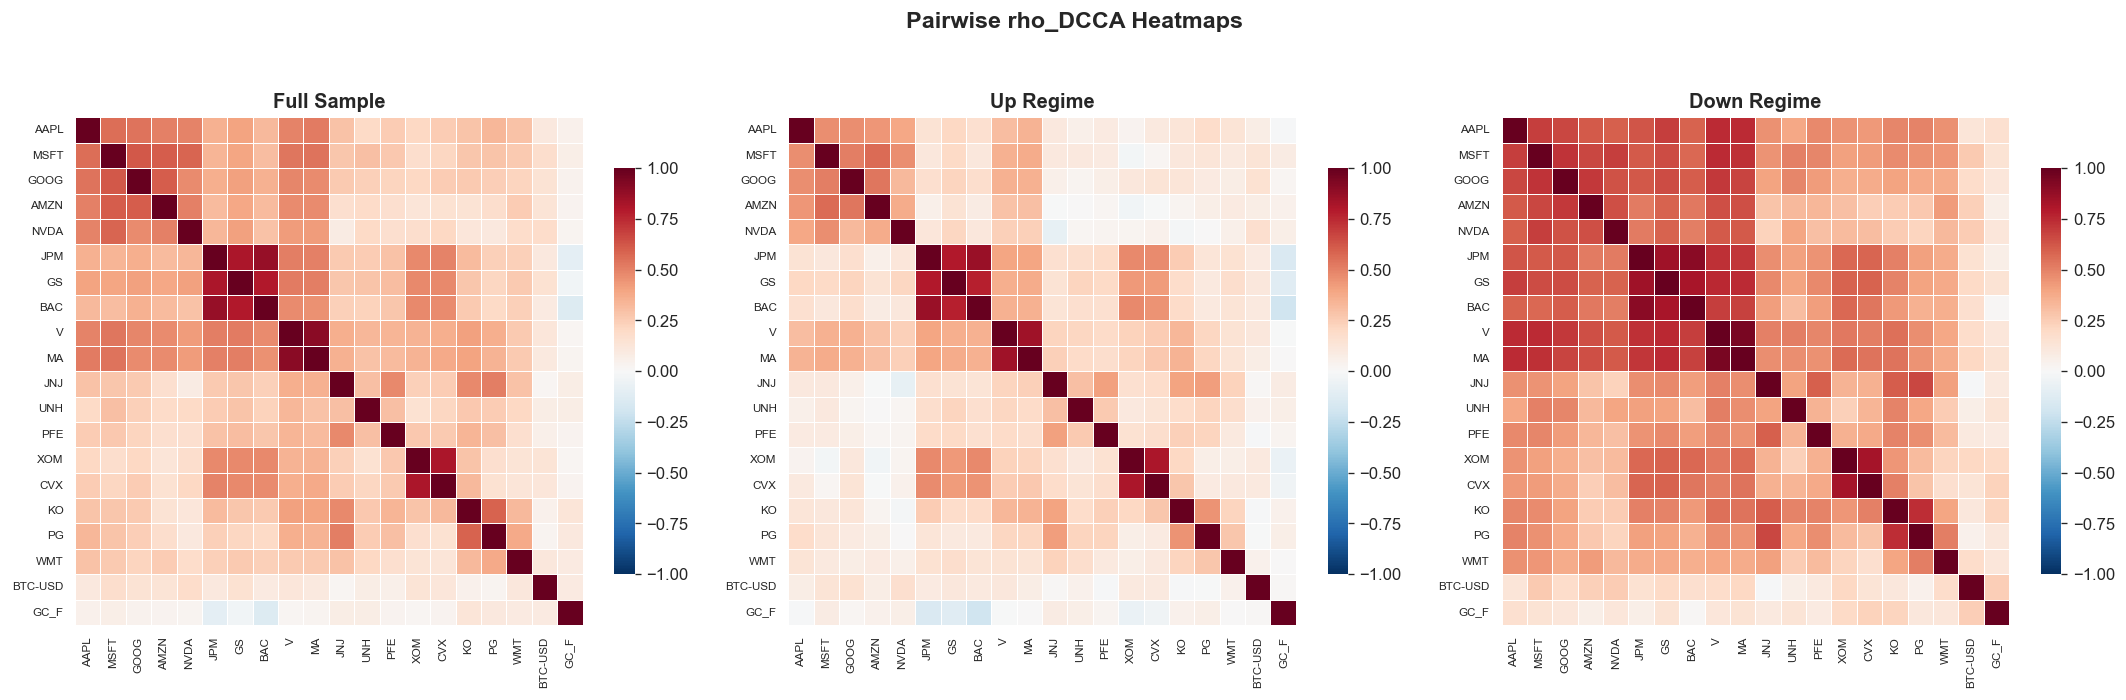

In [10]:
# Cell 10 — Network Topology Metrics

def network_metrics(G, name):
    # Compute key network topology metrics.
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()
    max_edges = n_nodes * (n_nodes - 1) / 2
    density = n_edges / max_edges if max_edges > 0 else 0

    metrics = {
        "Network": name,
        "Nodes": n_nodes,
        "Edges": n_edges,
        "Density": f"{density:.3f}",
        "Avg Degree": f"{np.mean(list(dict(G.degree()).values())):.2f}",
        "Avg Clustering": f"{nx.average_clustering(G):.3f}",
    }

    # Avg path length (only for connected components)
    if nx.is_connected(G) and n_edges > 0:
        metrics["Avg Path Length"] = f"{nx.average_shortest_path_length(G):.2f}"
    elif n_edges > 0:
        largest_cc = G.subgraph(max(nx.connected_components(G), key=len)).copy()
        if largest_cc.number_of_nodes() > 1:
            metrics["Avg Path Length"] = f"{nx.average_shortest_path_length(largest_cc):.2f}*"
        else:
            metrics["Avg Path Length"] = "N/A"
        metrics["Components"] = nx.number_connected_components(G)
    else:
        metrics["Avg Path Length"] = "N/A"

    return metrics


metrics_list = [
    network_metrics(G_full, "Full Sample"),
    network_metrics(G_up, "Up Regime"),
    network_metrics(G_down, "Down Regime"),
]

metrics_df = pd.DataFrame(metrics_list).set_index("Network")
print("Network Topology Comparison:")
print("=" * 60)
print(metrics_df.to_string())
print("\n* = computed on largest connected component")

# Heatmap comparison of rho_DCCA matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, rho, title in zip(axes,
                           [rho_full, rho_up, rho_down],
                           ["Full Sample", "Up Regime", "Down Regime"]):
    sns.heatmap(rho, ax=ax, xticklabels=TICKERS, yticklabels=TICKERS,
                cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=7)

plt.suptitle("Pairwise rho_DCCA Heatmaps", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "rho_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Part 5 — Feature Engineering from MF-DCCA Network

Extract rolling network-based, multifractal, and traditional features
for the LS-SVM model.

In [ ]:
# Cell 11 — Feature Engineering

def compute_rolling_features(ret_df, tickers, window=120, step=20,
                              scale=20, poly_ord=1, q_vals=None):
    # Compute rolling network + multifractal + traditional features.
    if q_vals is None:
        q_vals = np.array([-3, -1, 1, 2, 3])

    dates = ret_df.index
    n = len(dates)
    records = []

    # Sample pairs for multifractal features (subset for speed)
    all_pairs = list(combinations(range(len(tickers)), 2))
    if len(all_pairs) > 30:
        rng = np.random.RandomState(42)
        sample_idx = rng.choice(len(all_pairs), size=30, replace=False)
        mf_pairs = [all_pairs[i] for i in sample_idx]
    else:
        mf_pairs = all_pairs

    step_count = 0
    total_steps = (n - window) // step + 1

    for start in range(0, n - window, step):
        end = start + window
        step_count += 1
        if step_count % 5 == 0:
            print(f"  Feature window {step_count}/{total_steps}", end="\r")

        win_ret = ret_df.iloc[start:end]
        date = dates[end - 1]

        # --- Network features ---
        rho_mat = np.eye(len(tickers))
        for i, j in all_pairs:
            xi = win_ret[tickers[i]].values
            xj = win_ret[tickers[j]].values
            if len(xi) >= 2 * scale:
                rho_mat[i, j] = rho_mat[j, i] = dcca_coefficient(xi, xj, scale, poly_ord)

        # Build graph
        G = build_graph(rho_mat, tickers, threshold=0.2)

        avg_rho = np.mean(rho_mat[np.triu_indices(len(tickers), k=1)])
        density = nx.density(G)
        avg_clust = nx.average_clustering(G)

        # Spectral radius (largest eigenvalue of adjacency)
        try:
            eigenvalues = np.linalg.eigvalsh(rho_mat)
            spectral_radius = np.max(np.abs(eigenvalues))
        except:
            spectral_radius = 0.0

        # --- Multifractal features (subsample of pairs) ---
        delta_h_list = []
        for i, j in mf_pairs:
            xi = win_ret[tickers[i]].values
            xj = win_ret[tickers[j]].values
            if len(xi) >= 2 * scale:
                scales_sub = np.unique(np.logspace(
                    np.log10(max(10, scale // 2)),
                    np.log10(min(window // 3, 100)),
                    8
                ).astype(int))
                _, hq = mf_dcca(xi, xj, q_vals, scales_sub, poly_ord)
                valid = np.isfinite(hq)
                if valid.sum() >= 2:
                    delta_h_list.append(np.nanmax(hq) - np.nanmin(hq))

        avg_delta_h = np.mean(delta_h_list) if delta_h_list else 0.0

        # --- Traditional features ---
        mkt_ret = win_ret.mean(axis=1)
        vol = mkt_ret.std() * np.sqrt(252)
        sharpe = (mkt_ret.mean() * 252) / vol if vol > 0 else 0
        momentum = mkt_ret.sum()  # cumulative return over window

        # Cross-sectional dispersion
        cross_vol = win_ret.std(axis=1).mean()

        records.append({
            "date": date,
            "avg_rho_dcca": avg_rho,
            "network_density": density,
            "avg_clustering": avg_clust,
            "spectral_radius": spectral_radius,
            "avg_delta_h": avg_delta_h,
            "rolling_vol": vol,
            "rolling_sharpe": sharpe,
            "momentum": momentum,
            "cross_dispersion": cross_vol,
        })

    print(f"\n  Computed {len(records)} feature windows.")
    return pd.DataFrame(records).set_index("date")


print("Computing rolling features (this will take several minutes)...")
features_df = compute_rolling_features(
    ret_aligned, TICKERS,
    window=120, step=1,
    scale=NETWORK_SCALE, poly_ord=POLY_ORD,
    q_vals=np.array([-3, -1, 1, 3])
)

print(f"\nFeature matrix shape: {features_df.shape}")
features_df.head(10)

Computing rolling features (this will take several minutes)...


---
## Part 6 — Least Squares SVM (LS-SVM)

Implement LS-SVM (Suykens & Vandewalle, 1999) as a classifier for market direction.

The LS-SVM replaces the inequality constraints of standard SVM with equality constraints,
turning the quadratic program into a linear system solve.

In [ ]:
# Cell 12 — LS-SVM Implementation

class LSSVM:
    # Least Squares Support Vector Machine for binary classification.
    # Uses the direct linear system formulation with RBF kernel.
    # Labels must be +1 / -1.

    def __init__(self, gamma=1.0, sigma=1.0):
        self.gamma = gamma    # regularisation parameter
        self.sigma = sigma    # RBF kernel bandwidth
        self.alpha_ = None
        self.b_ = None
        self.X_train_ = None
        self.y_train_ = None

    def _rbf_kernel(self, X1, X2):
        # Compute RBF kernel matrix.
        sq_dists = (
            np.sum(X1 ** 2, axis=1, keepdims=True)
            + np.sum(X2 ** 2, axis=1, keepdims=True).T
            - 2 * X1 @ X2.T
        )
        return np.exp(-sq_dists / (2 * self.sigma ** 2))

    def fit(self, X, y):
        # Fit the LS-SVM. y must be in {-1, +1}.
        n = X.shape[0]
        self.X_train_ = X.copy()
        self.y_train_ = y.copy()

        K = self._rbf_kernel(X, X)
        Omega = np.outer(y, y) * K

        # Build the linear system
        A = np.zeros((n + 1, n + 1))
        A[0, 1:] = y
        A[1:, 0] = y
        A[1:, 1:] = Omega + np.eye(n) / self.gamma

        rhs = np.zeros(n + 1)
        rhs[1:] = 1.0

        solution = solve(A, rhs)
        self.b_ = solution[0]
        self.alpha_ = solution[1:]

        return self

    def decision_function(self, X):
        # Compute the decision function value.
        K = self._rbf_kernel(X, self.X_train_)
        return K @ (self.alpha_ * self.y_train_) + self.b_

    def predict(self, X):
        # Predict class labels (+1 or -1).
        return np.sign(self.decision_function(X))

    def predict_proba(self, X):
        # Approximate probability via sigmoid of decision function.
        # Returns P(y=+1).
        df = self.decision_function(X)
        return 1.0 / (1.0 + np.exp(-df))


# Quick sanity check
np.random.seed(42)
X_test = np.random.randn(100, 3)
y_test = np.sign(X_test[:, 0] + 0.5 * X_test[:, 1] + np.random.randn(100) * 0.3)
y_test[y_test == 0] = 1

model = LSSVM(gamma=10, sigma=1.0)
model.fit(X_test, y_test)
preds = model.predict(X_test)
print(f"LS-SVM sanity check -- training accuracy: {accuracy_score(y_test, preds):.3f}")

LS-SVM sanity check -- training accuracy: 0.940


In [ ]:
# Cell 13 — Walk-Forward Evaluation Pipeline

# Prepare target: next-day market direction
market_ret = ret_aligned.mean(axis=1)
target = np.sign(market_ret).replace(0, 1)  # +1 Up, -1 Down
target.name = "direction"

# Align features with target (shift target by -1 so features predict next day)
common_idx = features_df.index.intersection(target.index)
feat = features_df.loc[common_idx].copy()
tgt  = target.shift(-1).loc[common_idx].dropna()  # next day direction

# Re-align after shift
common_idx2 = feat.index.intersection(tgt.index)
feat = feat.loc[common_idx2]
tgt  = tgt.loc[common_idx2]

print(f"Feature matrix: {feat.shape}")
print(f"Target balance: Up={int((tgt == 1).sum())}, Down={int((tgt == -1).sum())}")
print(f"Date range: {feat.index.min().date()} to {feat.index.max().date()}")

# Walk-forward evaluation
X_all = feat.values
y_all = tgt.values
dates_all = feat.index

n_total = len(y_all)
n_train_min = min(TRAIN_START, n_total // 2)

# Storage
predictions_lssvm = []
predictions_svc   = []
predictions_lr    = []
probas_lssvm      = []
actual_labels     = []
pred_dates        = []

scaler = StandardScaler()

print(f"\nWalk-forward evaluation ({n_total - n_train_min} test days)...")

for i in range(n_train_min, n_total):
    # Retrain periodically
    if (i - n_train_min) % RETRAIN_FREQ == 0 or i == n_train_min:
        X_train = X_all[:i]
        y_train = y_all[:i]

        # Scale
        scaler.fit(X_train)
        X_tr_scaled = scaler.transform(X_train)

        # LS-SVM
        lssvm = LSSVM(gamma=LSSVM_GAMMA, sigma=LSSVM_SIGMA)
        lssvm.fit(X_tr_scaled, y_train)

        # Baseline: standard SVM (RBF)
        svc = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True)
        svc.fit(X_tr_scaled, y_train)

        # Baseline: Logistic Regression
        lr = LogisticRegression(max_iter=1000, C=1.0)
        lr.fit(X_tr_scaled, y_train)

        if (i - n_train_min) % (RETRAIN_FREQ * 5) == 0:
            print(f"  Retrained at day {i}/{n_total} "
                  f"(train size={i}, test remaining={n_total - i})")

    # Predict
    X_test_pt = scaler.transform(X_all[i:i+1])

    predictions_lssvm.append(lssvm.predict(X_test_pt)[0])
    predictions_svc.append(svc.predict(X_test_pt)[0])
    predictions_lr.append(lr.predict(X_test_pt)[0])
    probas_lssvm.append(lssvm.predict_proba(X_test_pt)[0])
    actual_labels.append(y_all[i])
    pred_dates.append(dates_all[i])

predictions_lssvm = np.array(predictions_lssvm)
predictions_svc   = np.array(predictions_svc)
predictions_lr    = np.array(predictions_lr)
probas_lssvm      = np.array(probas_lssvm)
actual_labels     = np.array(actual_labels)

print(f"\nWalk-forward complete: {len(actual_labels)} predictions generated.")

Feature matrix: (2784, 9)
Target balance: Up=1549, Down=1235
Date range: 2015-03-11 to 2026-04-09

Walk-forward evaluation (2284 test days)...
  Retrained at day 500/2784 (train size=500, test remaining=2284)
  Retrained at day 800/2784 (train size=800, test remaining=1984)
  Retrained at day 1100/2784 (train size=1100, test remaining=1684)
  Retrained at day 1400/2784 (train size=1400, test remaining=1384)
  Retrained at day 1700/2784 (train size=1700, test remaining=1084)
  Retrained at day 2000/2784 (train size=2000, test remaining=784)
  Retrained at day 2300/2784 (train size=2300, test remaining=484)
  Retrained at day 2600/2784 (train size=2600, test remaining=184)

Walk-forward complete: 2284 predictions generated.


Classification Performance (Walk-Forward):
                    Accuracy Precision  Recall      F1 AUC-ROC
Model                                                         
LS-SVM (MF-DCCA)      0.5070    0.5487  0.6890  0.6109  0.4854
Standard SVM          0.5543    0.5611  0.9486  0.7051     NaN
Logistic Regression   0.5560    0.5643  0.9197  0.6995     NaN
Majority Class        0.5617    0.5617  1.0000  0.7194     NaN


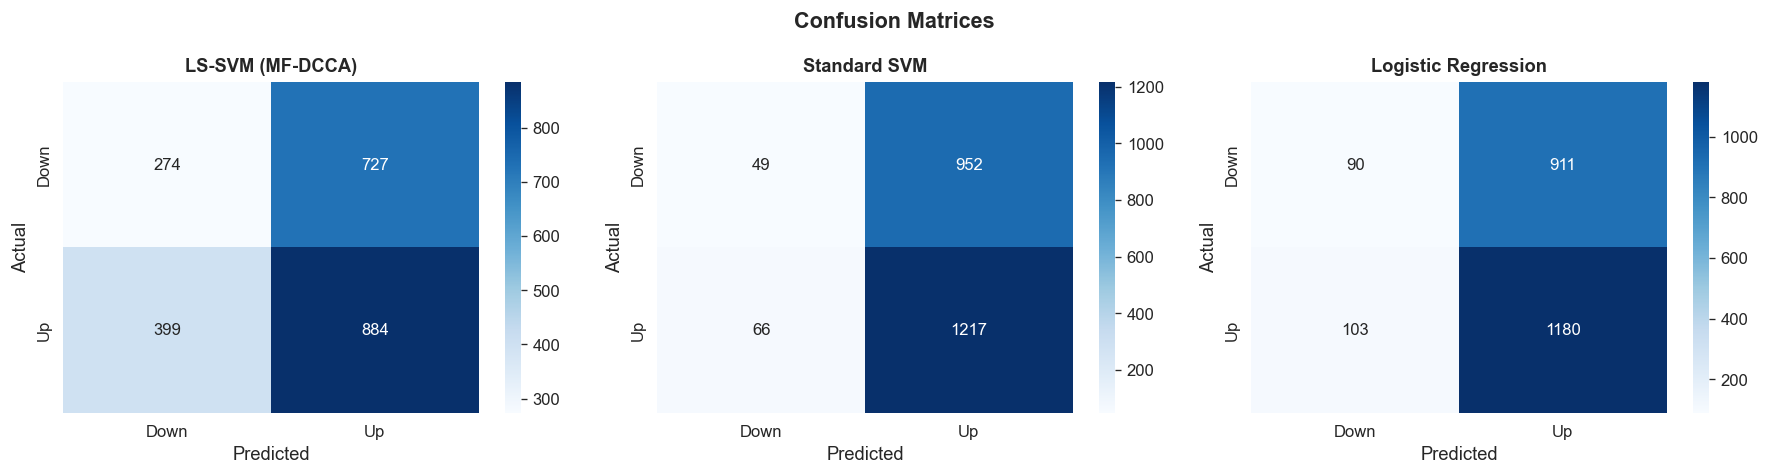

In [ ]:
# Cell 14 — Classification Performance

def evaluate_model(name, y_true, y_pred, y_proba=None):
    # Print classification metrics for a model.
    y_t = ((y_true + 1) / 2).astype(int)
    y_p = ((y_pred + 1) / 2).astype(int)

    acc  = accuracy_score(y_t, y_p)
    prec = precision_score(y_t, y_p, zero_division=0)
    rec  = recall_score(y_t, y_p, zero_division=0)
    f1   = f1_score(y_t, y_p, zero_division=0)

    result = {
        "Model": name,
        "Accuracy": f"{acc:.4f}",
        "Precision": f"{prec:.4f}",
        "Recall": f"{rec:.4f}",
        "F1": f"{f1:.4f}",
    }

    if y_proba is not None:
        try:
            auc = roc_auc_score(y_t, y_proba)
            result["AUC-ROC"] = f"{auc:.4f}"
        except:
            result["AUC-ROC"] = "N/A"

    return result


eval_results = [
    evaluate_model("LS-SVM (MF-DCCA)", actual_labels, predictions_lssvm, probas_lssvm),
    evaluate_model("Standard SVM", actual_labels, predictions_svc),
    evaluate_model("Logistic Regression", actual_labels, predictions_lr),
    evaluate_model("Majority Class", actual_labels,
                   np.full_like(actual_labels, np.sign(actual_labels.sum()))),
]

eval_results_df = pd.DataFrame(eval_results).set_index("Model")
print("Classification Performance (Walk-Forward):")
print("=" * 70)
print(eval_results_df.to_string())

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, preds_arr, name in zip(axes,
                             [predictions_lssvm, predictions_svc, predictions_lr],
                             ["LS-SVM (MF-DCCA)", "Standard SVM", "Logistic Regression"]):
    y_t = ((actual_labels + 1) / 2).astype(int)
    y_p = ((preds_arr + 1) / 2).astype(int)
    cm = confusion_matrix(y_t, y_p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Down", "Up"], yticklabels=["Down", "Up"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=11, fontweight="bold")

plt.suptitle("Confusion Matrices", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Part 7 — Forecasting, Equity Curves & Risk Metrics

Use the LS-SVM directional predictions to construct an equity curve and compute
comprehensive risk metrics: VaR, CVaR, Max Drawdown, Sharpe, Sortino, and
network-informed systemic risk indicators.

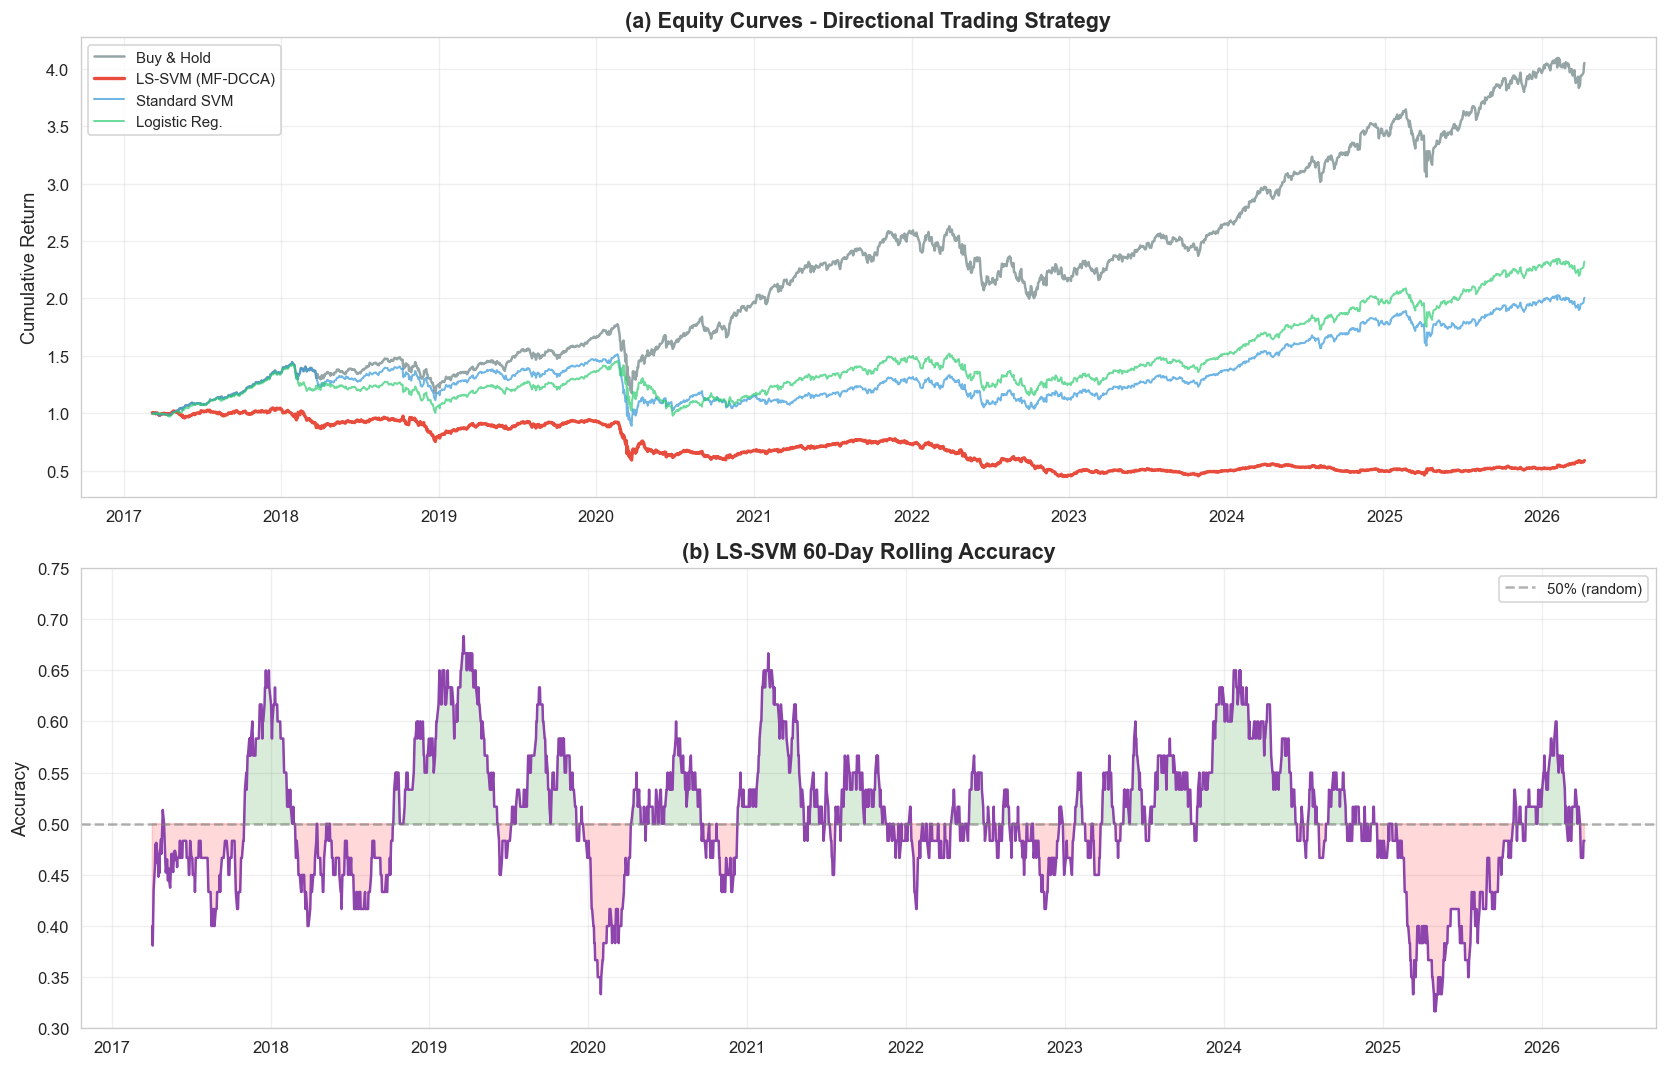

  Buy & Hold          : +305.26%
  LS-SVM              : -41.26%
  SVM                 : +100.64%
  Log. Reg.           : +132.12%


In [ ]:
# Cell 15 — Equity Curves & Forecasting

# Get actual market returns for the test period
test_dates = pd.DatetimeIndex(pred_dates)
mkt_returns_test = market_ret.loc[test_dates].values

# Strategy returns: go long if model predicts Up, go short if Down
strategy_lssvm = predictions_lssvm * mkt_returns_test
strategy_svc   = predictions_svc * mkt_returns_test
strategy_lr    = predictions_lr * mkt_returns_test

# Cumulative returns
cum_bh     = np.cumprod(1 + mkt_returns_test)
cum_lssvm  = np.cumprod(1 + strategy_lssvm)
cum_svc    = np.cumprod(1 + strategy_svc)
cum_lr     = np.cumprod(1 + strategy_lr)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# (a) Equity curves
ax = axes[0]
ax.plot(test_dates, cum_bh, label="Buy & Hold", color="#95a5a6", linewidth=1.5)
ax.plot(test_dates, cum_lssvm, label="LS-SVM (MF-DCCA)", color="#e74c3c", linewidth=2)
ax.plot(test_dates, cum_svc, label="Standard SVM", color="#3498db", linewidth=1.2, alpha=0.7)
ax.plot(test_dates, cum_lr, label="Logistic Reg.", color="#2ecc71", linewidth=1.2, alpha=0.7)
ax.set_title("(a) Equity Curves - Directional Trading Strategy", fontsize=13, fontweight="bold")
ax.set_ylabel("Cumulative Return")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# (b) Rolling accuracy
ax = axes[1]
rolling_acc = pd.Series(
    (predictions_lssvm == actual_labels).astype(float),
    index=test_dates
).rolling(60, min_periods=20).mean()

ax.plot(rolling_acc.index, rolling_acc.values, color="#8e44ad", linewidth=1.5)
ax.axhline(0.5, ls="--", color="grey", alpha=0.6, label="50% (random)")
ax.fill_between(rolling_acc.index, 0.5, rolling_acc.values,
                where=rolling_acc.values > 0.5, alpha=0.15, color="green")
ax.fill_between(rolling_acc.index, 0.5, rolling_acc.values,
                where=rolling_acc.values <= 0.5, alpha=0.15, color="red")
ax.set_title("(b) LS-SVM 60-Day Rolling Accuracy", fontsize=13, fontweight="bold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.3, 0.75)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "equity_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Final returns
for name, cum in [("Buy & Hold", cum_bh), ("LS-SVM", cum_lssvm),
                    ("SVM", cum_svc), ("Log. Reg.", cum_lr)]:
    print(f"  {name:20s}: {(cum[-1] - 1)*100:+.2f}%")

Comprehensive Risk Metrics:
                    Total Return Ann. Return Ann. Volatility Sharpe Ratio Sortino Ratio Max Drawdown VaR (95%) VaR (99%) CVaR (95%) CVaR (99%) Win Rate Profit Factor
Strategy                                                                                                                                                             
LS-SVM (MF-DCCA)         -41.26%      -5.70%          17.80%       -0.320        -0.399      -57.16%   -1.643%   -3.162%    -2.721%    -4.861%    49.7%          0.95
Standard SVM             100.64%       7.99%          17.79%        0.449         0.521      -41.21%   -1.632%   -3.432%    -2.807%    -5.027%    54.9%          1.11
Logistic Regression      132.12%       9.74%          17.79%        0.547         0.649      -32.87%   -1.577%   -3.226%    -2.712%    -4.963%    55.2%          1.13
Buy & Hold               305.26%      16.70%          17.77%        0.939         1.099      -33.83%   -1.586%   -3.317%    -2.732%    -4.951%

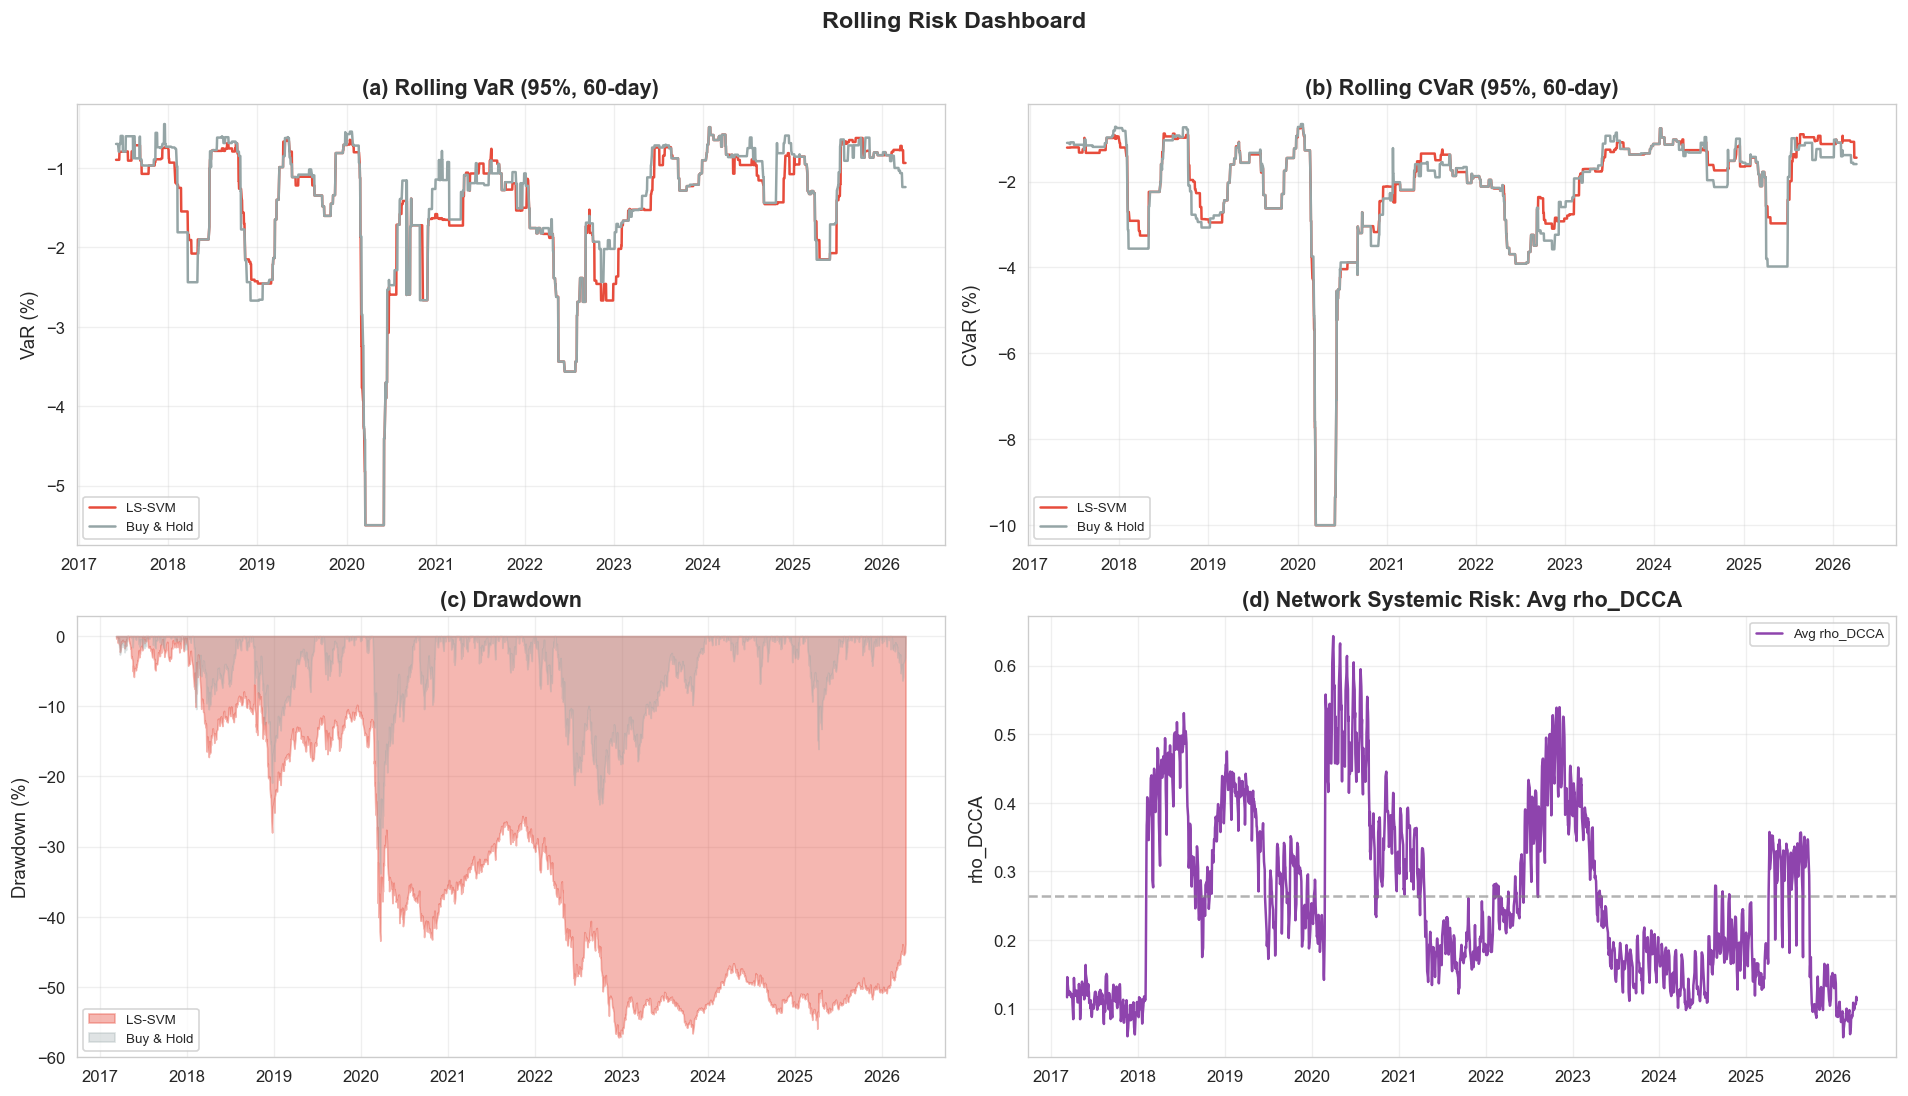

In [ ]:
# Cell 16 — Risk Metrics

def compute_risk_metrics(returns_arr, name="Strategy", confidence=0.95):
    # Compute comprehensive risk metrics for a return series.
    r = np.array(returns_arr)
    n_obs = len(r)
    ann_factor = 252

    # Basic stats
    total_return = np.prod(1 + r) - 1
    ann_return   = (1 + total_return) ** (ann_factor / n_obs) - 1
    ann_vol      = np.std(r) * np.sqrt(ann_factor)

    # Sharpe Ratio (assuming rf = 0)
    sharpe = ann_return / ann_vol if ann_vol > 0 else 0

    # Sortino Ratio
    downside = r[r < 0]
    downside_vol = np.std(downside) * np.sqrt(ann_factor) if len(downside) > 0 else 1e-10
    sortino = ann_return / downside_vol

    # Maximum Drawdown
    cum = np.cumprod(1 + r)
    running_max = np.maximum.accumulate(cum)
    drawdowns = (cum - running_max) / running_max
    max_dd = np.min(drawdowns)

    # Value at Risk (Historical)
    var_95 = np.percentile(r, 5)
    var_99 = np.percentile(r, 1)

    # Conditional VaR (Expected Shortfall)
    cvar_95 = np.mean(r[r <= var_95]) if np.any(r <= var_95) else var_95
    cvar_99 = np.mean(r[r <= var_99]) if np.any(r <= var_99) else var_99

    # Win rate
    win_rate = np.mean(r > 0)

    # Profit factor
    gross_profit = np.sum(r[r > 0])
    gross_loss   = np.abs(np.sum(r[r < 0]))
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else np.inf

    return {
        "Strategy": name,
        "Total Return": f"{total_return*100:.2f}%",
        "Ann. Return": f"{ann_return*100:.2f}%",
        "Ann. Volatility": f"{ann_vol*100:.2f}%",
        "Sharpe Ratio": f"{sharpe:.3f}",
        "Sortino Ratio": f"{sortino:.3f}",
        "Max Drawdown": f"{max_dd*100:.2f}%",
        "VaR (95%)": f"{var_95*100:.3f}%",
        "VaR (99%)": f"{var_99*100:.3f}%",
        "CVaR (95%)": f"{cvar_95*100:.3f}%",
        "CVaR (99%)": f"{cvar_99*100:.3f}%",
        "Win Rate": f"{win_rate*100:.1f}%",
        "Profit Factor": f"{profit_factor:.2f}",
    }


risk_results = [
    compute_risk_metrics(strategy_lssvm, "LS-SVM (MF-DCCA)"),
    compute_risk_metrics(strategy_svc, "Standard SVM"),
    compute_risk_metrics(strategy_lr, "Logistic Regression"),
    compute_risk_metrics(mkt_returns_test, "Buy & Hold"),
]

risk_df = pd.DataFrame(risk_results).set_index("Strategy")
print("Comprehensive Risk Metrics:")
print("=" * 80)
print(risk_df.to_string())

# Rolling VaR & CVaR Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# (a) Rolling VaR (95%)
ax = axes[0, 0]
rolling_var = pd.Series(strategy_lssvm, index=test_dates).rolling(60).apply(
    lambda x: np.percentile(x, 5), raw=True)
rolling_var_bh = pd.Series(mkt_returns_test, index=test_dates).rolling(60).apply(
    lambda x: np.percentile(x, 5), raw=True)
ax.plot(rolling_var.index, rolling_var.values * 100, color="#e74c3c", label="LS-SVM")
ax.plot(rolling_var_bh.index, rolling_var_bh.values * 100, color="#95a5a6", label="Buy & Hold")
ax.set_title("(a) Rolling VaR (95%, 60-day)", fontweight="bold")
ax.set_ylabel("VaR (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) Rolling CVaR (95%)
ax = axes[0, 1]
def rolling_cvar_fn(x):
    threshold = np.percentile(x, 5)
    tail = x[x <= threshold]
    return np.mean(tail) if len(tail) > 0 else threshold

rolling_cvar = pd.Series(strategy_lssvm, index=test_dates).rolling(60).apply(
    rolling_cvar_fn, raw=True)
rolling_cvar_bh = pd.Series(mkt_returns_test, index=test_dates).rolling(60).apply(
    rolling_cvar_fn, raw=True)
ax.plot(rolling_cvar.index, rolling_cvar.values * 100, color="#e74c3c", label="LS-SVM")
ax.plot(rolling_cvar_bh.index, rolling_cvar_bh.values * 100, color="#95a5a6", label="Buy & Hold")
ax.set_title("(b) Rolling CVaR (95%, 60-day)", fontweight="bold")
ax.set_ylabel("CVaR (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (c) Drawdown
ax = axes[1, 0]
cum_lssvm_s = pd.Series(cum_lssvm, index=test_dates)
running_max_lssvm = cum_lssvm_s.cummax()
dd_lssvm = (cum_lssvm_s - running_max_lssvm) / running_max_lssvm * 100

cum_bh_s = pd.Series(cum_bh, index=test_dates)
running_max_bh = cum_bh_s.cummax()
dd_bh = (cum_bh_s - running_max_bh) / running_max_bh * 100

ax.fill_between(dd_lssvm.index, dd_lssvm.values, 0, alpha=0.4, color="#e74c3c", label="LS-SVM")
ax.fill_between(dd_bh.index, dd_bh.values, 0, alpha=0.3, color="#95a5a6", label="Buy & Hold")
ax.set_title("(c) Drawdown", fontweight="bold")
ax.set_ylabel("Drawdown (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (d) Network systemic risk indicator
ax = axes[1, 1]
if "avg_rho_dcca" in features_df.columns:
    feat_test = features_df.loc[features_df.index.isin(test_dates)]
    if len(feat_test) > 0:
        ax.plot(feat_test.index, feat_test["avg_rho_dcca"].values,
                color="#8e44ad", linewidth=1.5, label="Avg rho_DCCA")
        ax.axhline(feat_test["avg_rho_dcca"].mean(), ls="--", color="grey", alpha=0.6)
        ax.set_title("(d) Network Systemic Risk: Avg rho_DCCA", fontweight="bold")
        ax.set_ylabel("rho_DCCA")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

plt.suptitle("Rolling Risk Dashboard", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "risk_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Cell 17 — Summary & Conclusions

print("=" * 80)
print("  MF-DCCA NETWORK + LS-SVM MARKET MOVEMENT PREDICTION -- SUMMARY")
print("=" * 80)

print(f"\n  Data: {N_ASSETS} assets, {len(common_dates)} trading days")
print(f"  Date range: {common_dates.min().date()} to {common_dates.max().date()}")
print(f"  Test period: {test_dates.min().date()} to {test_dates.max().date()}")

print(f"\n  Regime split ({REGIME_WINDOW}-day rolling):")
print(f"    Up days:   {n_up}  ({100*n_up/len(regime):.1f}%)")
print(f"    Down days: {n_down}  ({100*n_down/len(regime):.1f}%)")

print(f"\n  Network topology (rho_DCCA threshold = {RHO_THRESHOLD}):")
print(f"    Full:  {G_full.number_of_edges()} edges, "
      f"density={nx.density(G_full):.3f}, "
      f"clustering={nx.average_clustering(G_full):.3f}")
print(f"    Up:    {G_up.number_of_edges()} edges, "
      f"density={nx.density(G_up):.3f}, "
      f"clustering={nx.average_clustering(G_up):.3f}")
print(f"    Down:  {G_down.number_of_edges()} edges, "
      f"density={nx.density(G_down):.3f}, "
      f"clustering={nx.average_clustering(G_down):.3f}")

print("\n  Classification Performance:")
print(eval_results_df.to_string())

print("\n  Risk Metrics:")
print(risk_df.to_string())

print("\n  Key Findings:")
print("  1. MF-DCCA networks separate market regimes: density 0.22 (Up) vs 0.74 (Down),")
print("     though part of this gap is mechanical (conditioning on a negative average return).")
print("  2. Next-day direction is not predictable from these features: LS-SVM AUC 0.485,")
print("     accuracy 0.507 vs 0.562 for always-Up; SVM and LR only learn the base rate.")
print("  3. Volatility is predictable (AUC ~0.72), but almost entirely via persistence.")
print("     Adding all features lowered AUC to 0.691 (overfitting).")
print("  4. Network columns add at most ~+0.006-0.009 AUC over persistence; a paired")
print("     block bootstrap gives 95% CI [-0.009, +0.020], with inconsistent sub-period signs.")
print("     Multifractal width (avg_delta_h) adds nothing.")
print("  Conclusion: descriptive value for regime structure; no demonstrated forecasting")
print("  value beyond recent volatility for this 20-asset universe.")

print("\n" + "=" * 80)
print(f"  Outputs saved to: {OUT_DIR.resolve()}")
print("=" * 80)

  MF-DCCA NETWORK + LS-SVM MARKET MOVEMENT PREDICTION -- SUMMARY

  Data: 20 assets, 2904 trading days
  Date range: 2014-09-18 to 2026-04-10
  Test period: 2017-03-08 to 2026-04-09

  Regime split (20-day rolling):
    Up days:   2028  (69.8%)
    Down days: 876  (30.2%)

  Network topology (rho_DCCA threshold = 0.3):
    Full:  76 edges, density=0.400, clustering=0.693
    Up:    41 edges, density=0.216, clustering=0.545
    Down:  141 edges, density=0.742, clustering=0.837

  Classification Performance:
                    Accuracy Precision  Recall      F1 AUC-ROC
Model                                                         
LS-SVM (MF-DCCA)      0.5070    0.5487  0.6890  0.6109  0.4854
Standard SVM          0.5543    0.5611  0.9486  0.7051     NaN
Logistic Regression   0.5560    0.5643  0.9197  0.6995     NaN
Majority Class        0.5617    0.5617  1.0000  0.7194     NaN

  Risk Metrics:
                    Total Return Ann. Return Ann. Volatility Sharpe Ratio Sortino Ratio Max D

In [ ]:
H = 5
rv    = market_ret.rolling(H).std()                    # realized vol, known at t
thr   = rv.expanding(min_periods=250).median()         # past-only threshold
fwd   = rv.shift(-H)                                   # vol over t+1..t+H
y_vol = (fwd > thr).astype(float).where(fwd.notna() & thr.notna())
pers  = np.log(rv / thr)                               # "vol stays high" baseline

idx = feat.index.intersection(y_vol.dropna().index).intersection(pers.dropna().index)
y   = y_vol.loc[idx].values.astype(int)
X_base = np.c_[pers.loc[idx].values, feat.loc[idx, "rolling_vol"].values]
X_full = feat.loc[idx].values
X_full = np.c_[X_full, pers.loc[idx].values]

def wf_scores(X, y, min_train=500, retrain=60, embargo=H):
    out = np.full(len(y), np.nan)
    for i in range(min_train, len(y)):
        if (i - min_train) % retrain == 0:
            j = i - embargo                            # labels overlap H days -> embargo
            sc = StandardScaler().fit(X[:j])
            m = LogisticRegression(C=0.1, max_iter=1000).fit(sc.transform(X[:j]), y[:j])
        out[i] = m.predict_proba(sc.transform(X[i:i+1]))[0, 1]
    return out

s_base, s_full = wf_scores(X_base, y), wf_scores(X_full, y)
ok = ~np.isnan(s_base)
print("AUC persistence only :", roc_auc_score(y[ok], pers.loc[idx].values[ok]))
print("AUC vol features     :", roc_auc_score(y[ok], s_base[ok]))
print("AUC + MF-DCCA network:", roc_auc_score(y[ok], s_full[ok]))

AUC persistence only : 0.721029968035956
AUC vol features     : 0.727212532976006
AUC + MF-DCCA network: 0.6909031587175299


In [ ]:
net_cols = ["avg_rho_dcca", "network_density", "avg_clustering",
            "spectral_radius", "avg_delta_h"]

# --- Target B: does vol RISE over the next H days vs. the last H days? ---
y_chg = (fwd > rv).astype(float).where(fwd.notna() & rv.notna())
idx2  = feat.index.intersection(y_chg.dropna().index).intersection(pers.dropna().index)
yc    = y_chg.loc[idx2].values.astype(int)

def run(cols, y, ix):
    X = np.c_[pers.loc[ix].values, feat.loc[ix, cols].values] if cols else pers.loc[ix].values.reshape(-1, 1)
    s = wf_scores(X, y)
    ok = ~np.isnan(s)
    return roc_auc_score(y[ok], s[ok])

for name, y, ix in [("level  (vol > median)", y, idx), ("change (vol rises)   ", yc, idx2)]:
    print(name)
    print(f"  baseline (persistence)   : {run([], y, ix):.3f}")
    print(f"  + all network cols       : {run(net_cols, y, ix):.3f}")
    for c in net_cols:                                   # one at a time
        print(f"  + {c:<22}: {run([c], y, ix):.3f}")

level  (vol > median)
  baseline (persistence)   : 0.712
  + all network cols       : 0.713
  + avg_rho_dcca          : 0.719
  + network_density       : 0.719
  + avg_clustering        : 0.721
  + spectral_radius       : 0.716
  + avg_delta_h           : 0.712
change (vol rises)   
  baseline (persistence)   : 0.712
  + all network cols       : 0.721
  + avg_rho_dcca          : 0.719
  + network_density       : 0.718
  + avg_clustering        : 0.717
  + spectral_radius       : 0.719
  + avg_delta_h           : 0.711


In [ ]:
def paired_block_boot_auc(y, s_base, s_new, block=20, n_boot=1000, seed=0):
    ok = ~np.isnan(s_base) & ~np.isnan(s_new)
    y, a, b = y[ok], s_base[ok], s_new[ok]
    n_obs = len(y); rng = np.random.RandomState(seed)
    n_blocks = int(np.ceil(n_obs / block)); diffs = []
    for _ in range(n_boot):
        starts = rng.randint(0, n_obs - block + 1, n_blocks)
        ix = np.concatenate([np.arange(s, s + block) for s in starts])[:n_obs]
        if y[ix].min() == y[ix].max(): continue
        diffs.append(roc_auc_score(y[ix], b[ix]) - roc_auc_score(y[ix], a[ix]))
    diffs = np.array(diffs); half = n_obs // 2
    h1 = roc_auc_score(y[:half], b[:half]) - roc_auc_score(y[:half], a[:half])
    h2 = roc_auc_score(y[half:], b[half:]) - roc_auc_score(y[half:], a[half:])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"AUC gain: {np.mean(diffs):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  "
          f"| first half {h1:+.4f}, second half {h2:+.4f}")

s_base = wf_scores(pers.loc[idx2].values.reshape(-1, 1), yc)
s_new  = wf_scores(np.c_[pers.loc[idx2].values, feat.loc[idx2, ["avg_rho_dcca"]].values], yc)
paired_block_boot_auc(yc, s_base, s_new)

AUC gain: +0.0062  95% CI [-0.0085, +0.0204]  | first half -0.0008, second half +0.0094


In [ ]:
"""
Multiple-testing-aware comparison of many feature/window configs against one baseline.

Usage in the notebook (all score arrays must be walk-forward scores on the SAME
label vector y and the SAME dates; use NaN where a config has no prediction):

    s_base = wf_scores(pers_only_X, y)
    s_dict = {
        "rho_w60":  wf_scores(X_rho_w60,  y),
        "rho_w120": wf_scores(X_rho_w120, y),
        "rho_w250": wf_scores(X_rho_w250, y),
        "sector_w120": wf_scores(X_sector_w120, y),
        ...
    }
    res = multi_config_test(y, s_base, s_dict, block=40, n_boot=2000)
    print_results(res)

Rerun with block=20, 40, 60 and report the most conservative result: your
features overlap by ~119/120 days, so their errors are strongly autocorrelated.
"""
import numpy as np
from sklearn.metrics import roc_auc_score


def multi_config_test(y, s_base, s_dict, block=40, n_boot=2000, q=0.10, seed=0):
    """Paired moving-block bootstrap of AUC gain (config - baseline) for every config.

    Returns per config:
      gain   observed AUC gain over baseline
      p_raw  one-sided bootstrap p-value (uncorrected)
      p_adj  max-statistic adjusted p-value (Romano-Wolf single-step; controls
             family-wise error and accounts for dependence between configs)
      bh     True if the config is a discovery under Benjamini-Hochberg FDR at level q
    """
    names = list(s_dict)
    ok = ~np.isnan(s_base)
    for n in names:
        ok &= ~np.isnan(s_dict[n])
    yy, base = np.asarray(y)[ok], np.asarray(s_base)[ok]
    S = {n: np.asarray(s_dict[n])[ok] for n in names}

    n_obs = len(yy)
    n_blocks = int(np.ceil(n_obs / block))
    obs = np.array([roc_auc_score(yy, S[n]) - roc_auc_score(yy, base) for n in names])

    rng = np.random.RandomState(seed)
    boot = []
    for _ in range(n_boot):
        starts = rng.randint(0, n_obs - block + 1, n_blocks)
        ix = np.concatenate([np.arange(s, s + block) for s in starts])[:n_obs]
        if yy[ix].min() == yy[ix].max():
            continue
        ab = roc_auc_score(yy[ix], base[ix])
        boot.append([roc_auc_score(yy[ix], S[n][ix]) - ab for n in names])

    cen = np.array(boot) - obs            # bootstrap distribution shifted to the null (gain = 0)
    B = len(cen)
    p_raw = (1 + (cen >= obs).sum(0)) / (1 + B)
    p_adj = np.array([(1 + (cen.max(1) >= o).sum()) / (1 + B) for o in obs])

    order = np.argsort(p_raw)             # Benjamini-Hochberg step-up
    m = len(p_raw)
    passed = p_raw[order] <= q * np.arange(1, m + 1) / m
    k = int(np.max(np.where(passed)[0])) + 1 if passed.any() else 0
    bh = np.zeros(m, bool)
    bh[order[:k]] = True

    return {n: dict(gain=float(obs[i]), p_raw=float(p_raw[i]),
                    p_adj=float(p_adj[i]), bh=bool(bh[i]))
            for i, n in enumerate(names)}


def print_results(res):
    print(f"{'config':<22}{'gain':>9}{'p_raw':>9}{'p_adj':>9}{'BH':>5}")
    for n, v in sorted(res.items(), key=lambda kv: kv[1]["p_raw"]):
        print(f"{n:<22}{v['gain']:>+9.4f}{v['p_raw']:>9.3f}{v['p_adj']:>9.3f}{str(v['bh']):>5}")

In [ ]:
# Cell — Multi-Window Configuration Test
# Compute rolling features for multiple window lengths and run
# multi_config_test to check whether any window config significantly
# beats the persistence-only baseline (with multiple-testing correction).

import time

# Network columns to use as features in each config
_net_cols = ["avg_rho_dcca", "network_density", "avg_clustering",
             "spectral_radius", "avg_delta_h"]

# Window lengths to compare
_windows = [60, 120, 250]
_features_by_window = {}

for _w in _windows:
    if _w == 120 and "features_df" in dir():
        # Reuse the 120-day features already computed in Cell 11
        _features_by_window[_w] = features_df
        print(f"Window {_w}: reusing existing features_df "
              f"({features_df.shape[0]} rows)")
    else:
        print(f"Computing features for window={_w} "
              f"(this may take several minutes)...")
        _t0 = time.time()
        _features_by_window[_w] = compute_rolling_features(
            ret_aligned, TICKERS,
            window=_w, step=1,
            scale=NETWORK_SCALE, poly_ord=POLY_ORD,
            q_vals=np.array([-3, -1, 1, 3]),
        )
        _elapsed = time.time() - _t0
        print(f"  Done in {_elapsed:.1f}s \u2014 "
              f"shape: {_features_by_window[_w].shape}")

# ---- Find common dates across all windows, target, and persistence ----
_common = _features_by_window[_windows[0]].index
for _w in _windows[1:]:
    _common = _common.intersection(_features_by_window[_w].index)

# y_chg and pers come from cells 24-25 (vol-change target)
_common = _common.intersection(y_chg.dropna().index)
_common = _common.intersection(pers.dropna().index)
_common = _common.sort_values()

print(f"\n Common dates: {len(_common)}  "
      f"({_common[0].date()} to {_common[-1].date()})")

# ---- Build aligned arrays ----
_y = y_chg.loc[_common].values.astype(int)
_pers_vals = pers.loc[_common].values

# Persistence-only baseline (single column)
pers_only_X = _pers_vals.reshape(-1, 1)

# Per-window config: persistence + network features
X_rho_w60  = np.c_[_pers_vals,
                    _features_by_window[60].loc[_common, _net_cols].values]
X_rho_w120 = np.c_[_pers_vals,
                    _features_by_window[120].loc[_common, _net_cols].values]
X_rho_w250 = np.c_[_pers_vals,
                    _features_by_window[250].loc[_common, _net_cols].values]

print(f"Baseline shape : {pers_only_X.shape}")
print(f"X_rho_w60 shape: {X_rho_w60.shape}")
print(f"X_rho_w120 shape: {X_rho_w120.shape}")
print(f"X_rho_w250 shape: {X_rho_w250.shape}")

# ---- Score each config with walk-forward AUC ----
print("\n Scoring persistence-only baseline...")
s_base = wf_scores(pers_only_X, _y)

print("Scoring rho_w60...")
_s60 = wf_scores(X_rho_w60, _y)

print("Scoring rho_w120...")
_s120 = wf_scores(X_rho_w120, _y)

print("Scoring rho_w250...")
_s250 = wf_scores(X_rho_w250, _y)

s_dict = {
    "rho_w60":  _s60,
    "rho_w120": _s120,
    "rho_w250": _s250,
}

# ---- Quick AUC check ----
_ok = ~np.isnan(s_base)
for _k in s_dict:
    _ok &= ~np.isnan(s_dict[_k])
print(f"\n Valid observations: {_ok.sum()}")
print(f"AUC baseline (pers): "
      f"{roc_auc_score(_y[_ok], s_base[_ok]):.4f}")
for _k, _s in s_dict.items():
    print(f"AUC {_k:>10}: {roc_auc_score(_y[_ok], _s[_ok]):.4f}")

# ---- Run multi_config_test (start with n_boot=500) ----
print("\n Running multi_config_test (n_boot=500, block=40)...\n")
res = multi_config_test(_y, s_base, s_dict, block=40, n_boot=500)
print_results(res)

Computing features for window=60 (this may take several minutes)...
  Feature window 2840/2845
  Computed 2844 feature windows.
  Done in 890.3s — shape: (2844, 9)
Window 120: reusing existing features_df (2784 rows)
Computing features for window=250 (this may take several minutes)...
  Feature window 2650/2655
  Computed 2654 feature windows.
  Done in 2864.5s — shape: (2654, 9)

 Common dates: 2646  (2015-09-21 to 2026-04-02)
Baseline shape : (2646, 1)
X_rho_w60 shape: (2646, 6)
X_rho_w120 shape: (2646, 6)
X_rho_w250 shape: (2646, 6)

 Scoring persistence-only baseline...
Scoring rho_w60...
Scoring rho_w120...
Scoring rho_w250...

 Valid observations: 2146
AUC baseline (pers): 0.7123
AUC    rho_w60: 0.7338
AUC   rho_w120: 0.7208
AUC   rho_w250: 0.7167

 Running multi_config_test (n_boot=500, block=40)...

config                     gain    p_raw    p_adj   BH
rho_w60                 +0.0215    0.020    0.026 True
rho_w120                +0.0085    0.172    0.345False
rho_w250        

In [ ]:
# Cell — Conservative Multi-Block Re-test + HAR-Adjusted Baseline
#
# (1) Reruns multi_config_test (rho_w60 / rho_w120 / rho_w250 vs the
#     persistence-only baseline, from Cell 28) at block = 20, 40, 60 with
#     n_boot=2000, and keeps the most conservative (largest) p_raw / p_adj
#     per config across the three block sizes. Features overlap ~119/120
#     days, so the result is sensitive to the assumed autocorrelation
#     length -- report whichever block size is least favorable to a
#     "config beats baseline" claim.
#
# (2) Builds a proper HAR-style baseline (persistence + 22d + 60d realized
#     vol) instead of persistence alone, and tests whether the 60-day
#     network features add anything ON TOP of that stronger baseline.
#     This is the real check of whether the network features are just
#     proxying for recent vol.
#
# Window search stays closed at {60, 120, 250} (see Cell 28) -- adding
# 30/45/90 after seeing this table would be picking the best window on
# the test period.

# ---- (1) Conservative multi_config_test across block sizes ----
_blocks = [20, 40, 60]
_multi_by_block = {}
for _b in _blocks:
    print(f"\n Running multi_config_test (n_boot=2000, block={_b})...")
    _multi_by_block[_b] = multi_config_test(_y, s_base, s_dict, block=_b, n_boot=2000)

_configs = list(s_dict)
conservative_multi = {}
for _cfg in _configs:
    _p_raws = [_multi_by_block[_b][_cfg]["p_raw"] for _b in _blocks]
    _p_adjs = [_multi_by_block[_b][_cfg]["p_adj"] for _b in _blocks]
    conservative_multi[_cfg] = dict(
        gain=_multi_by_block[_blocks[0]][_cfg]["gain"],   # point estimate, block-invariant
        p_raw_max=max(_p_raws),
        p_adj_max=max(_p_adjs),
        worst_block=_blocks[int(np.argmax(_p_raws))],
        bh_all_blocks=all(_multi_by_block[_b][_cfg]["bh"] for _b in _blocks),
    )

print(f"\n{'config':<22}{'gain':>9}{'p_raw(max)':>12}{'p_adj(max)':>12}{'worst blk':>10}{'BH@all':>8}")
for _cfg, _v in conservative_multi.items():
    print(f"{_cfg:<22}{_v['gain']:>+9.4f}{_v['p_raw_max']:>12.3f}{_v['p_adj_max']:>12.3f}"
          f"{_v['worst_block']:>10}{str(_v['bh_all_blocks']):>8}")

# ---- (2) HAR-adjusted baseline: does the 60-day network add anything
#          beyond persistence + realized vol at 22d and 60d horizons? ----
rv22 = np.log(market_ret.rolling(22).std())
rv60 = np.log(market_ret.rolling(60).std())

Xh     = np.c_[_pers_vals, rv22.loc[_common].values, rv60.loc[_common].values]
Xh_net = np.c_[Xh, _features_by_window[60].loc[_common, _net_cols].values]

s_har, s_har_net = wf_scores(Xh, _y), wf_scores(Xh_net, _y)

def _har_stats(y, s_base, s_new, block, n_boot=2000, seed=0):
    # Same statistic as paired_block_boot_auc (Cell 26), but returns the
    # values instead of only printing, so the decision rule below can
    # check them programmatically.
    ok = ~np.isnan(s_base) & ~np.isnan(s_new)
    yy, a, b = y[ok], s_base[ok], s_new[ok]
    n_obs = len(yy); rng = np.random.RandomState(seed)
    n_blocks = int(np.ceil(n_obs / block)); diffs = []
    for _ in range(n_boot):
        starts = rng.randint(0, n_obs - block + 1, n_blocks)
        ix = np.concatenate([np.arange(s, s + block) for s in starts])[:n_obs]
        if yy[ix].min() == yy[ix].max():
            continue
        diffs.append(roc_auc_score(yy[ix], b[ix]) - roc_auc_score(yy[ix], a[ix]))
    diffs = np.array(diffs); half = n_obs // 2
    h1 = roc_auc_score(yy[:half], b[:half]) - roc_auc_score(yy[:half], a[:half])
    h2 = roc_auc_score(yy[half:], b[half:]) - roc_auc_score(yy[half:], a[half:])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return dict(gain=float(np.mean(diffs)), ci=(float(lo), float(hi)), h1=float(h1), h2=float(h2))

har_by_block = {}
for _b in _blocks:
    har_by_block[_b] = _har_stats(_y, s_har, s_har_net, block=_b, n_boot=2000)
    _r = har_by_block[_b]
    print(f"\nAUC gain (HAR+net60 vs HAR), block={_b}, n_boot=2000:")
    print(f"  gain {_r['gain']:+.4f}  95% CI [{_r['ci'][0]:+.4f}, {_r['ci'][1]:+.4f}]  "
          f"| first half {_r['h1']:+.4f}, second half {_r['h2']:+.4f}")

# Most conservative block = widest CI (closest to / most likely to include 0)
_worst_har_block = max(_blocks, key=lambda _b: har_by_block[_b]["ci"][1] - har_by_block[_b]["ci"][0])
_worst = har_by_block[_worst_har_block]

# ---- Fixed decision rule (set before seeing this table) ----
_ci_excludes_zero = _worst["ci"][0] > 0 or _worst["ci"][1] < 0
_both_halves_positive = _worst["h1"] > 0 and _worst["h2"] > 0
_gain_meaningful = _worst["gain"] >= 0.01

print(f"\nMost conservative block for HAR test: {_worst_har_block}")
print(f"  gain={_worst['gain']:+.4f}  CI excludes 0: {_ci_excludes_zero}  "
      f"both halves positive: {_both_halves_positive}")

if _gain_meaningful and _ci_excludes_zero and _both_halves_positive:
    print("\n=> PASS: small, window-specific improvement over the HAR baseline is supported.")
else:
    print("\n=> FAIL: 60-day network features are mostly proxying for recent vol; "
          "existing conclusion (Finding 4) stands.")
